<a href="https://colab.research.google.com/github/SkrybaOtis/Systemy_AI/blob/main/SystemyAI_Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [1]:
print("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


*Twoja odpowiedź:*

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [2]:
model, version, accuracy, deployed = "NeuralNet", 2, 0.94, True

In [3]:
print(type(model), type(version), type(accuracy), type(deployed))
s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

<class 'str'> <class 'int'> <class 'float'> <class 'bool'>
A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [4]:
acc = [0.78, 0.86, 0.92, 0.81]
n = len(acc)
mean_acc = sum(acc)/n

std_acc = (sum((x - mean_acc)**2 for x in acc)/n)**(1/2)

In [5]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [6]:
text = "AI systems learn from data. AI systems make predictions from data"
text = text.lower().replace(".", "").split()
counts = {}
for t in text:
  if t in counts.keys():
    counts[t] = counts[t] + 1
  else:
    counts[t] = 1

v_max = 0
for v in counts.values():
  if v > v_max:
    v_max = v

most_common = []
for k, v in counts.items():
  if v == v_max:
    most_common.append(k)

In [7]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [8]:
def performance_label(score):
  if score < 0 or score > 1:
    raise ValueError
  if not (type(score) in [float, int]):
    raise TypeError

  if score < 0.75:
    result = "weak"
  elif score >= 0.75 and score <= 0.90:
    result = "average"
  elif score > 0.90:
    result = "strong"

  return result

scores = [0.72, 0.81, 0.93, 0.88]
mean_ok = 0.0
mean_ok_n = 0
for s in scores:
  p_l_res = performance_label(s)
  print(s, p_l_res)
  if p_l_res != "weak":
    mean_ok += s
    mean_ok_n +=1
mean_ok = mean_ok/mean_ok_n


0.72 weak
0.81 average
0.93 strong
0.88 average


In [9]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [10]:
results = {"SVM" : 0.81, "DecisionTree" : 0.74, "NeuralNet" : 0.92}
results["Transformer"] = 0.95
mean_results = sum([v for v in results.values()])/len(results)
print(mean_results)
above_mean = []
for k, v in results.items():
  if v > mean_results:
    above_mean.append(k)

def print_ranking(results):
  desc = {k: v for k, v in sorted(results.items(), key=lambda item: item[1], reverse=True)}

  for i, (k, v) in enumerate(desc.items()):
    print(f"{i+1}. {k} – {v}")
    if i==0:
      res = k

  return res

print_ranking(results)


0.855
1. Transformer – 0.95
2. NeuralNet – 0.92
3. SVM – 0.81
4. DecisionTree – 0.74


'Transformer'

In [11]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.7
2. A – 0.5
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [12]:
raw = [0.83, 0.92, 1.05, -0.12, 0.78, None, "0.9", True]
def clean_scores(raw):
  valid = []
  for s in raw:
    if (type(s) in [float, int]) and s >= 0 and s <= 1:
      valid.append(s)
  n_invalid = len(raw) - len(valid)
  valid_mean = sum(valid)/len(valid)
  print(f"Poprawne: {len(valid)} | Błędne: {n_invalid} | Średnia (poprawnych): {valid_mean:.2f}")
  return (valid, n_invalid)

clean_scores(raw)

Poprawne: 3 | Błędne: 5 | Średnia (poprawnych): 0.84


([0.83, 0.92, 0.78], 5)

In [13]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84
Poprawne: 2 | Błędne: 1 | Średnia (poprawnych): 0.50
B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [14]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [15]:
def summarize_model(info):
  print(info["name"])
  info["mean_score"] = sum(v for v in info["metrics"].values())/len(info["metrics"].values())
  print(info["mean_score"])
  readiness_status = "Model gotowy do wdrożenia" if info["mean_score"] >= 0.9 else "Model wymaga poprawy"
  print(readiness_status)
  return info

new_model_info = summarize_model(model_info)
print(new_model_info)

NeuralNet
0.88
Model wymaga poprawy
{'name': 'NeuralNet', 'version': '1.2', 'metrics': {'accuracy': 0.91, 'precision': 0.88, 'recall': 0.85}, 'status': 'trained', 'mean_score': 0.88}


In [16]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

X
0.94
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [17]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [18]:
TP, FN = 0, 0
FP, TN = 0, 0
for y_t, y_p in zip(y_true, y_pred):
  #print(y_t, " : ", y_p)
  if y_t == 1:
    if y_p == 1:
      TP += 1
    else:
      FN += 1
  elif y_t == 0:
    if y_p == 1:
      FP += 1
    else:
      TN += 1

#print(TP,", ", FN)
#print(FP,", ", TN)

print(f"TP={TP} FP={FP} FN={FN} TN={TN}")

precision = TP/(TP+FP)
recall = TP/(TP+FN)
f1 = (2*precision*recall)/(precision+recall)

print(f"precision={precision} recall={recall} F1={f1}")

TP=3 FP=1 FN=2 TN=4
precision=0.75 recall=0.6 F1=0.6666666666666665


In [19]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [20]:
import numpy as np

def binary_metrics(y_true, y_pred):
  y_t, y_p = np.array(y_true), np.array(y_pred)
  TP = np.sum((y_t == 1) & (y_p == 1))
  FP = np.sum((y_t == 0) & (y_p == 1))
  FN = np.sum((y_t == 1) & (y_p == 0))
  TN = np.sum((y_t == 0) & (y_p == 0))
  print(TP, FN)
  print(FP, TN)

  accuracy = (TP + TN) / (TP + FP + FN + TN)
  precision = TP / (TP + FP) if (TP+FP) != 0 else 0.0
  recall = TP / (TP + FN) if (TP+FN) != 0 else 0.0
  f1 = (2*precision*recall)/(precision+recall) if (precision+recall) != 0 else 0.0

  return {
      "TP" : TP,
      "FP" : FP,
      "FN" : FN,
      "TN" : TN,
      "accuracy" : accuracy,
      "precision" : precision,
      "recall" : recall,
      "f1" : f1
  }

b_m = binary_metrics(y_true, y_pred)

3 2
1 4


In [21]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

3 2
1 4
0 1
0 3
C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [22]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
 f1_score, confusion_matrix, classification_report)

c_m = confusion_matrix(y_true, y_pred) # tablica 2x2
a_s = accuracy_score(y_true, y_pred) # jedna liczba
p_s = precision_score(y_true, y_pred)
r_s = recall_score(y_true, y_pred)
f_s = f1_score(y_true, y_pred)

#W dokumentacji jest napisane:
#   By definition a confusion matrix C is such that C_{i, j}
#   is equal to the number of observations
#   known to be in group i and
#   predicted to be in group j.
#   Thus in binary classification, the count of
#   true negatives is C_{0,0}, false negatives is C_{1,0},
#   true positives is C_{1,1}, false positives is C_{0,1}
# Returns
#   C : ndarray of shape (n_classes, n_classes)
#   Confusion matrix whose i-th row and j-th
#   column entry indicates the number of samples
#   with true label being i-th class
#   and predicted label being j-th class.
#
#Układ jest następujący:
#             predykcja 0     predykcja 1
#  prawda 0       TN              FP
#  prawda 1       FN              TP


print(c_m, "\n", a_s, "\n", p_s, "\n", r_s, "\n", f_s)

print(
  np.isclose(b_m['TN'], c_m[0][0]), "\n",
  np.isclose(b_m['FP'], c_m[0][1]), "\n",
  np.isclose(b_m['FN'], c_m[1][0]), "\n",
  np.isclose(b_m['TP'], c_m[1][1]), "\n",
  np.isclose(b_m['accuracy'], a_s), "\n",
  np.isclose(b_m['precision'], p_s), "\n",
  np.isclose(b_m['recall'], r_s), "\n",
  np.isclose(b_m['f1'], f_s), "\n",

)


[[4 1]
 [2 3]] 
 0.7 
 0.75 
 0.6 
 0.6666666666666666
True 
 True 
 True 
 True 
 True 
 True 
 True 
 True 



---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Moja odpowiedź:*

- accuracy dla:
1.   zawsze-zero (TP = 0%, TN = 95%, FP = 0%, FN = 5%) ≈ 0.95
2.   zaszumiany (TP + TN = 90%, FP + FN = 10%) ≈ 0.90


- wyższą accuracy będzie miał model: zawsze-zero

- zaszumiony model będzie miał precision bliżej: 0.9


Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [23]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [24]:
import pandas as pd

y_t, y_z, y_n = make_data(0.05)

print(binary_metrics(y_t, y_z))
print(binary_metrics(y_t, y_n))

ps = [0.5, 0.3, 0.1, 0.05, 0.01]

rows = []
for p in ps:
  y_t, y_z, y_n = make_data(p)
  b_m = binary_metrics(y_t, y_z)
  rows.append({
      'p': p,
      'model': 'zawsze-zero',
      'accuracy': b_m['accuracy'],
      'precision': b_m['precision'],
      'recall': b_m['recall'],
      'f1': b_m['f1']
  })

  b_m = binary_metrics(y_t, y_n)
  rows.append({
      'p': p,
      'model': 'zaszumiony',
      'accuracy': b_m['accuracy'],
      'precision': b_m['precision'],
      'recall': b_m['recall'],
      'f1': b_m['f1']
  })

df = pd.DataFrame(rows)



0 508
0 9492
{'TP': np.int64(0), 'FP': np.int64(0), 'FN': np.int64(508), 'TN': np.int64(9492), 'accuracy': np.float64(0.9492), 'precision': 0.0, 'recall': np.float64(0.0), 'f1': 0.0}
470 38
926 8566
{'TP': np.int64(470), 'FP': np.int64(926), 'FN': np.int64(38), 'TN': np.int64(8566), 'accuracy': np.float64(0.9036), 'precision': np.float64(0.336676217765043), 'recall': np.float64(0.9251968503937008), 'f1': np.float64(0.49369747899159666)}
0 5015
0 4985
4543 472
492 4493
0 3043
0 6957
2759 284
680 6277
0 984
0 9016
893 91
873 8143
0 508
0 9492
470 38
926 8566
0 101
0 9899
96 5
959 8940


[0.5, 0.3, 0.1, 0.05, 0.01] 
 [0.4985 0.6957 0.9016 0.9492 0.9899] 
 [0.9036 0.9036 0.9036 0.9036 0.9036] 
 [0.90228401 0.8022681  0.50566251 0.33667622 0.09099526]


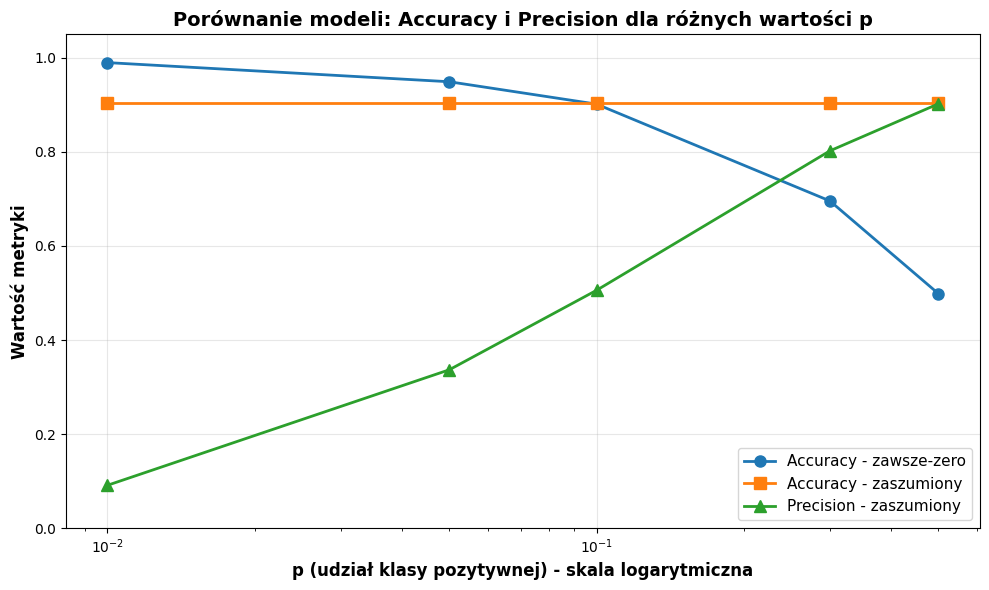

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

accuracy_zero = df[df['model'] == 'zawsze-zero']['accuracy'].values
accuracy_noisy = df[df['model'] == 'zaszumiony']['accuracy'].values
precision_noisy = df[df['model'] == 'zaszumiony']['precision'].values

print(ps, "\n", accuracy_zero, "\n", accuracy_noisy , "\n", precision_noisy )

plt.figure(figsize=(10, 6))

plt.semilogx(ps, accuracy_zero, marker='o', linewidth=2, markersize=8, label='Accuracy - zawsze-zero')
plt.semilogx(ps, accuracy_noisy, marker='s', linewidth=2, markersize=8, label='Accuracy - zaszumiony')
plt.semilogx(ps, precision_noisy, marker='^', linewidth=2, markersize=8, label='Precision - zaszumiony')

plt.xlabel('p (udział klasy pozytywnej) - skala logarytmiczna', fontsize=12, fontweight='bold')
plt.ylabel('Wartość metryki', fontsize=12, fontweight='bold')

plt.title('Porównanie modeli: Accuracy i Precision dla różnych wartości p', fontsize=14, fontweight='bold')

plt.legend(fontsize=11, loc='best')

plt.grid(True, alpha=0.3)

plt.ylim([0, 1.05])
plt.tight_layout()

plt.show()

In [26]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

1. Moje przewidywania z D1 się potwierdziły i mnie to zbytnio nie zaskoczyło, ponieważ policzyłem przewidywania według wzoru. (Może jedyne to w jaką stronę poszły rozbieżności od przewidywań.)
2. Dla p=0.01 wyższą accuracy ma model zawsze-zero. Jeśli chodzi o określenie użytności, to odpowiedź brzmi to zależy. Jak widać na wykresie zależy od tego z jakim zbiorem danych mamy do czynienia, ale także zależy od tego, co dany model ma wykrywać.
3. Malenie p pogłębia dysproporcję klas. Coraz większą przewagę zdobywa klasa negatywna, więc coraz rzadziej model poprawnie wykrywa pozytywny przypadek. W skrócie: coraz mniejsza proporcja TP, a coraz większa FP do całości, a przecież wzór na precision to precision = TP/(TP+FP)
4. Zaproponuję recall jako metrykę główną, bo lepiej wysłać zdrowego pacjenta na nadmierne badania niż przeoczyć chorego. FP - pacjent zostanie wysłany na dodatkowe badania diagnostyczne i co najwyżej się trochę postresuje, FN - pacjent ma zagrożenie zdrowia i życia, a zostanie wysłany do domu jako "zdrowy" (zostaje liczyć na efekt placebo)

---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [27]:
# Twoje rozwiązanie